# Step #1 Load the Data

In [1]:
# A tutorial for this file is available at www.relataly.com
# Tested with Python 3.12, TensorFlow 2.21, Keras 3.15, pandas 3.0, and yfinance 1.5

import keras
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
import yfinance as yf
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="white", rc={"axes.spines.right": False, "axes.spines.top": False})
keras.utils.set_random_seed(42)

print(f"TensorFlow version: {tf.__version__}")
print(f"Available GPUs: {len(tf.config.list_physical_devices('GPU'))}")

# Use a fixed, recent endpoint so the tutorial produces reproducible train/test sets.
start_date = "2010-01-01"
end_date = "2026-01-01"
stock_name = "S&P 500"
symbol = "^GSPC"

df = yf.download(
    symbol,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    multi_level_index=False,
    progress=False,
)
if df.empty:
    raise RuntimeError("yfinance returned no data for ^GSPC")

print(df.shape)
df.head()

TensorFlow version: 2.21.0


Available GPUs: 0


(4024, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,1132.989990,1133.869995,1116.560059,1116.560059,3991400000
2010-01-05,1136.520020,1136.630005,1129.660034,1132.660034,2491020000
2010-01-06,1137.140015,1139.189941,1133.949951,1135.709961,4972660000
2010-01-07,1141.689941,1142.459961,1131.319946,1136.270020,5270680000
2010-01-08,1144.979980,1145.390015,1136.219971,1140.520020,4389590000


# Step #2 Explore the Data

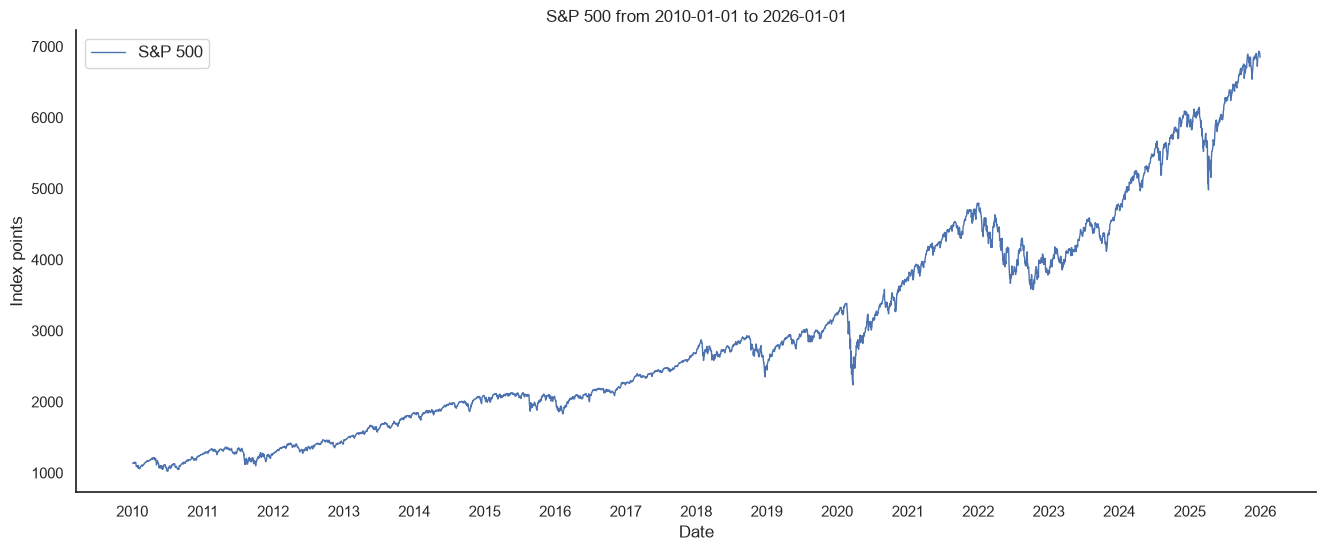

In [2]:
years = mdates.YearLocator()
_, ax = plt.subplots(figsize=(16, 6))
ax.xaxis.set_major_locator(years)
sns.lineplot(x=df.index, y=df["Close"], ax=ax, label=stock_name, linewidth=1.0)
ax.set_title(f"{stock_name} from {start_date} to {end_date}")
ax.set_ylabel("Index points")
ax.legend(fontsize=12)
plt.show()

# Step #3 Scaling the Data

In [3]:
close_prices = df[["Close"]].dropna().copy()
train_size = int(len(close_prices) * 0.8)

# Fit preprocessing on the training period only to avoid leaking future price ranges.
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(close_prices.iloc[:train_size])
scaled_prices = scaler.transform(close_prices)

# Step #4 Creating the Input Shape 

In [4]:
sequence_length = 50


def create_sequences(values, sequence_length):
    features, targets = [], []
    for index in range(sequence_length, len(values)):
        features.append(values[index - sequence_length:index])
        targets.append(values[index, 0])

    return (
        np.asarray(features, dtype=np.float32),
        np.asarray(targets, dtype=np.float32),
    )


train_values = scaled_prices[:train_size]
test_values = scaled_prices[train_size - sequence_length:]
x_train, y_train = create_sequences(train_values, sequence_length)
x_test, y_test = create_sequences(test_values, sequence_length)

print(f"Training shapes: {x_train.shape}, {y_train.shape}")
print(f"Test shapes: {x_test.shape}, {y_test.shape}")

# The first test target follows the final 50 observations ending at the split.
assert np.isclose(x_test[0, -1, 0], scaled_prices[train_size - 1, 0])
assert np.isclose(y_test[0], scaled_prices[train_size, 0])

Training shapes: (3169, 50, 1), (3169,)
Test shapes: (805, 50, 1), (805,)


# Step #5 Designing the Model Architecture 

In [5]:
model = keras.Sequential(
    [
        keras.layers.Input(shape=(sequence_length, 1)),
        keras.layers.LSTM(50, return_sequences=True),
        keras.layers.LSTM(50),
        keras.layers.Dense(25, activation="relu"),
        keras.layers.Dense(1),
    ],
    name="sp500_lstm",
)
model.compile(optimizer=keras.optimizers.Adam(), loss="mean_squared_error")
model.summary()

Model: "sp500_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,901 (124.61 KB)

 Trainable params: 31,901 (124.61 KB)

 Non-trainable params: 0 (0.00 B)

# Step #6 Train the Univariate Model

In [6]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
)
history = model.fit(
    x_train,
    y_train,
    batch_size=32,
    epochs=20,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1,
)

Epoch 1/20


 1/90 ━━━━━━━━━━━━━━━━━━━━ 15:56 11s/step - loss: 0.0018

 2/90 ━━━━━━━━━━━━━━━━━━━━ 8s 99ms/step - loss: 9.7164e-04

 3/90 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - loss: 7.4240e-04

 4/90 ━━━━━━━━━━━━━━━━━━━━ 8s 94ms/step - loss: 6.1882e-04

 5/90 ━━━━━━━━━━━━━━━━━━━━ 7s 86ms/step - loss: 5.0253e-04

... (1,261 outputs left out)

87/90 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - loss: 2.5043e-04

88/90 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 2.5238e-04

89/90 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - loss: 2.5018e-04

90/90 ━━━━━━━━━━━━━━━━━━━━ 6s 68ms/step - loss: 2.5026e-04 - val_loss: 0.0013


# Step #7 Make Predictions

In [7]:
y_pred_scaled = model.predict(x_test, verbose=0)
y_pred = scaler.inverse_transform(y_pred_scaled).ravel()
y_test_unscaled = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

# Step #8 Evaluate Model Performance

In [8]:
absolute_percentage_errors = np.abs((y_test_unscaled - y_pred) / y_test_unscaled) * 100
mae = mean_absolute_error(y_test_unscaled, y_pred)
rmse = root_mean_squared_error(y_test_unscaled, y_pred)
mape = absolute_percentage_errors.mean()
median_ape = np.median(absolute_percentage_errors)

# A one-step persistence forecast predicts that tomorrow closes at today's value.
naive_pred = close_prices["Close"].iloc[train_size - 1:-1].to_numpy()
naive_mae = mean_absolute_error(y_test_unscaled, naive_pred)
naive_rmse = root_mean_squared_error(y_test_unscaled, naive_pred)

print(f"LSTM MAE: {mae:.2f} index points")
print(f"LSTM RMSE: {rmse:.2f} index points")
print(f"LSTM MAPE: {mape:.2f}%")
print(f"LSTM median absolute percentage error: {median_ape:.2f}%")
print(f"Persistence baseline MAE: {naive_mae:.2f} index points")
print(f"Persistence baseline RMSE: {naive_rmse:.2f} index points")

LSTM MAE: 237.18 index points
LSTM RMSE: 309.49 index points
LSTM MAPE: 4.14%
LSTM median absolute percentage error: 3.63%
Persistence baseline MAE: 35.17 index points
Persistence baseline RMSE: 50.65 index points


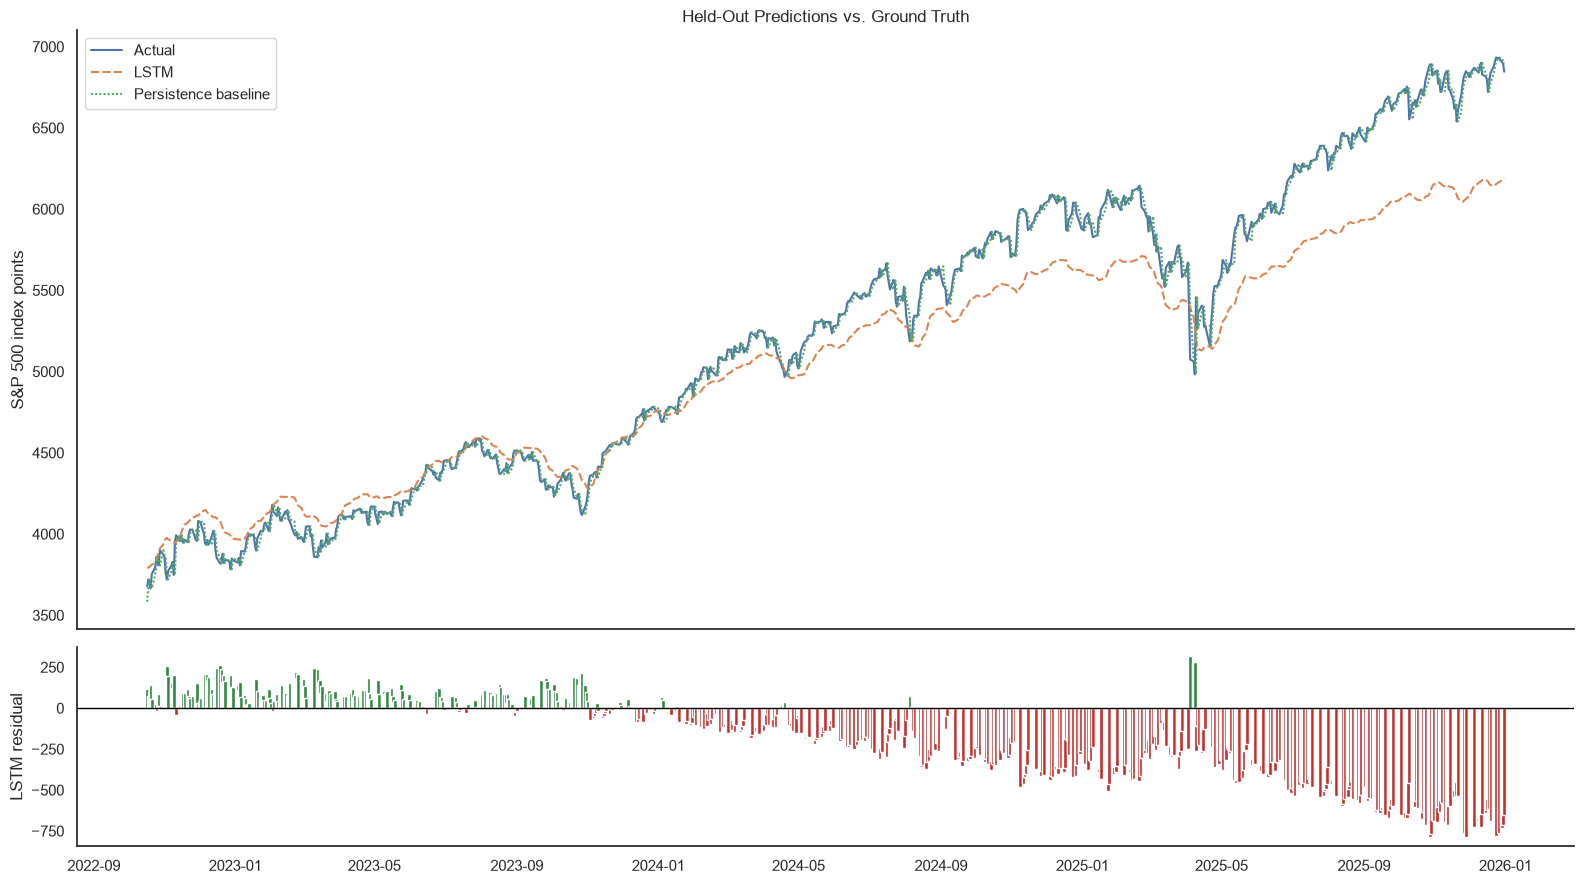

In [9]:
test_index = close_prices.index[train_size:]
evaluation = pd.DataFrame(
    {
        "Actual": y_test_unscaled,
        "LSTM": y_pred,
        "Persistence baseline": naive_pred,
    },
    index=test_index,
)
evaluation["LSTM residual"] = evaluation["LSTM"] - evaluation["Actual"]

_, (ax_price, ax_error) = plt.subplots(
    2,
    1,
    figsize=(16, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1]},
)
sns.lineplot(data=evaluation[["Actual", "LSTM", "Persistence baseline"]], ax=ax_price)
ax_price.set_title("Held-Out Predictions vs. Ground Truth")
ax_price.set_ylabel("S&P 500 index points")

colors = np.where(evaluation["LSTM residual"] >= 0, "#2B8A3E", "#C92A2A")
ax_error.bar(evaluation.index, evaluation["LSTM residual"], width=3, color=colors)
ax_error.axhline(0, color="black", linewidth=1)
ax_error.set_ylabel("LSTM residual")
plt.tight_layout()
plt.show()

# Step #9 Predict Next Day's Price

In [10]:
last_sequence_scaled = scaler.transform(close_prices.iloc[-sequence_length:])
x_next = last_sequence_scaled[np.newaxis, ...].astype(np.float32)
next_close_scaled = model.predict(x_next, verbose=0)
next_close = float(scaler.inverse_transform(next_close_scaled)[0, 0])

last_date = close_prices.index[-1].date()
last_close = float(close_prices["Close"].iloc[-1])
percent_change = (next_close / last_close - 1) * 100

print(f"Last observed {stock_name} close on {last_date}: {last_close:.2f}")
print(f"Illustrative next-session prediction: {next_close:.2f} ({percent_change:+.2f}%)")

Last observed S&P 500 close on 2025-12-31: 6845.50
Illustrative next-session prediction: 6190.69 (-9.57%)
